# Évaluation : référence contre fine-tuning complet

Ce notebook compare deux approches sur le même test de 624 radiographies :
1. la référence, avec ResNet-50 gelé et une régression logistique ;
2. le fine-tuning complet de ResNet-50, avec le meilleur modèle .

Toutes les métriques sont calculées au seuil de décision 0,5.

## 1. Imports et racine du projet

On retrouve la racine du projet et on recharge le package `src`, pour éviter les conflits avec d'autres installations.

In [10]:
import torch
from torch import nn
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import DataConfig, ModelConfig
from src.data import build_dataloaders
from src.features import POSITIVE_INDEX
from src.model import build_model
from src.train import predict
from src.utils import get_device

In [2]:
import sys
from pathlib import Path

racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
for nom in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[nom]
sys.path.insert(0, str(racine))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

from src.config import CLASS_NAMES, OUTPUT_DIR

print("Racine :", racine)
print("Classes :", CLASS_NAMES)

Racine : C:\Users\Administrator\Documents\projets_machine_learning\chest-xray-pneumonia
Classes : ('NORMAL', 'PNEUMONIA')


## 2. Chargement des résultats

On lit les métriques enregistrées par `features.py` et `train.py`, ainsi que l'historique d'entraînement du fine-tuning.

In [3]:
METRICS = OUTPUT_DIR / "metrics"

with open(METRICS / "features_logreg.json", encoding="utf-8") as f:
    ref = json.load(f)
with open(METRICS / "finetune_resnet50.json", encoding="utf-8") as f:
    ft = json.load(f)
with open(METRICS / "finetune_history.json", encoding="utf-8") as f:
    history = json.load(f)["historique"]

print("Référence : C =", ref["C_retenu"], "| balanced accuracy de validation", round(ref["balanced_accuracy_validation"], 4))
print("Fine-tuning : meilleure epoch =", ft["meilleure_epoch"], "| perte de validation", round(ft["meilleure_perte_validation"], 4))

Référence : C = 0.01 | balanced accuracy de validation 0.9648
Fine-tuning : meilleure epoch = 5 | perte de validation 0.0719


## 3. Tableau comparatif

Les métriques principales sont présentées côte à côte. La balanced accuracy compense le déséquilibre des classes. Les fausses alertes et les malades manqués sont donnés en nombre de cas, car ils ont un sens concret pour le rapport.

In [4]:
def resume(res):
    t = res["test"]
    cm = np.array(t["matrice_confusion"])
    return {
        "Balanced accuracy": t["balanced_accuracy"],
        "ROC AUC": t["roc_auc"],
        "Accuracy": t["accuracy"],
        "Rappel NORMAL": t["par_classe"]["NORMAL"]["recall"],
        "Rappel PNEUMONIA": t["par_classe"]["PNEUMONIA"]["recall"],
        "Précision PNEUMONIA": t["par_classe"]["PNEUMONIA"]["precision"],
        "Fausses alertes": int(cm[0, 1]),
        "Malades manqués": int(cm[1, 0]),
    }

comparaison = pd.DataFrame({
    "Référence (gelé + logistique)": resume(ref),
    "Fine-tuning complet": resume(ft),
}).round(4)
comparaison

,Référence (gelé + logistique),Fine-tuning complet
Balanced accuracy,0.7718,0.8564
ROC AUC,0.9498,0.9612
Accuracy,0.8237,0.8878
Rappel NORMAL,0.5641,0.7308
Rappel PNEUMONIA,0.9795,0.9821
Précision PNEUMONIA,0.7893,0.8587
Fausses alertes,102.0000,63.0000
Malades manqués,8.0000,7.0000


## 4. Matrices de confusion

La matrice montre, pour chaque classe réelle, combien d'images ont été classées dans chaque catégorie. La case en haut à droite (NORMAL classé PNEUMONIA) est celle des fausses alertes. La case en bas à gauche (PNEUMONIA classé NORMAL) est celle des malades manqués.

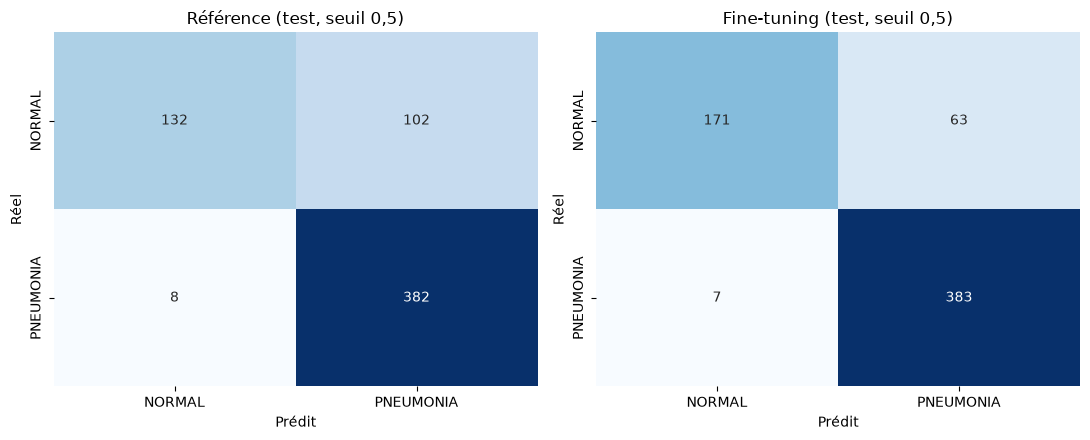

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (titre, res) in zip(axes, [("Référence", ref), ("Fine-tuning", ft)]):
    cm = np.array(res["test"]["matrice_confusion"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{titre} (test, seuil 0,5)")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
plt.tight_layout()
plt.show()

## 5. Rappel par classe

Le rappel mesure la part de vrais cas détectés. Pour la pneumonie, c'est le critère clinique principal : un malade non détecté est plus grave qu'une fausse alerte. Pour la classe NORMAL, il mesure la capacité à reconnaître les cas sains.

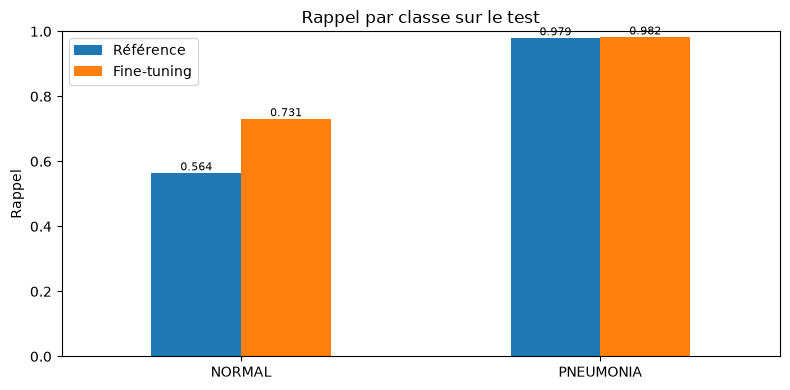

In [7]:
rappels = pd.DataFrame({
    "Référence": {c: ref["test"]["par_classe"][c]["recall"] for c in CLASS_NAMES},
    "Fine-tuning": {c: ft["test"]["par_classe"][c]["recall"] for c in CLASS_NAMES},
})
ax = rappels.plot(kind="bar", rot=0, figsize=(8, 4), ylim=(0, 1))
ax.set_title("Rappel par classe sur le test")
ax.set_ylabel("Rappel")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Courbes d'entraînement du fine-tuning

Les deux courbes de gauche montrent la perte pendant l'entraînement. Si la perte de validation remonte pendant que celle de train baisse, c'est du surapprentissage. La ligne grise marque la meilleure epoch, celle qui a été sauvegardée. La courbe de droite suit la balanced accuracy de validation.

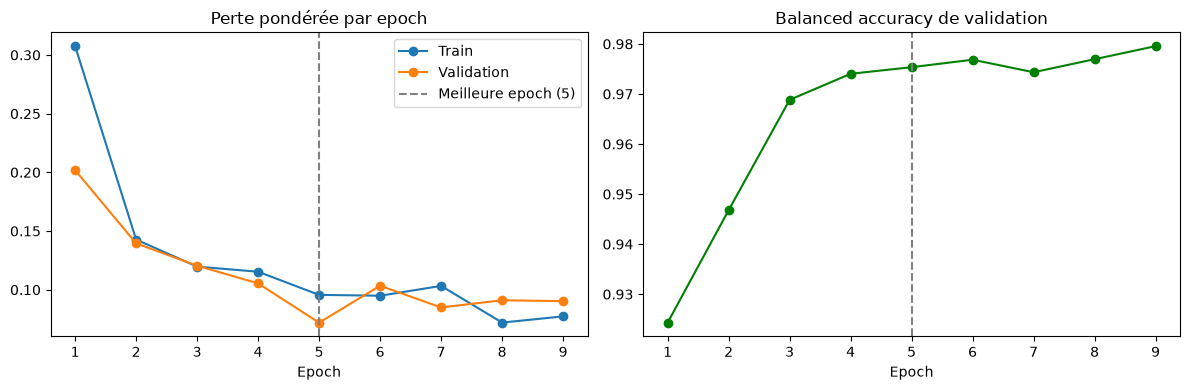

In [8]:
epoques = [h["epoch"] for h in history]
perte_train = [h["perte_train"] for h in history]
perte_val = [h["perte_validation"] for h in history]
ba_val = [h["balanced_accuracy_validation"] for h in history]
meilleure = ft["meilleure_epoch"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epoques, perte_train, marker="o", label="Train")
axes[0].plot(epoques, perte_val, marker="o", label="Validation")
axes[0].axvline(meilleure, color="grey", linestyle="--", label=f"Meilleure epoch ({meilleure})")
axes[0].set_title("Perte pondérée par epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epoques, ba_val, marker="o", color="green")
axes[1].axvline(meilleure, color="grey", linestyle="--")
axes[1].set_title("Balanced accuracy de validation")
axes[1].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## 7. Courbes ROC (optionnel, environ une minute)

La courbe ROC mesure la capacité de tri du modèle, indépendamment du seuil. Elle nécessite de recalculer les probabilités sur le test :
- pour le fine-tuning, on recharge le meilleur modèle sauvegardé ;
- pour la référence, on refait la régression logistique avec le C retenu, sur les caractéristiques déjà en cache.



2026-10-10 21:14:00,604 | INFO     | src.data | Entraînement : 4470 images, 2259 groupes
2026-10-10 21:14:00,604 | INFO     | src.data | Validation   : 746 images, 376 groupes
2026-10-10 21:14:00,604 | INFO     | src.data | Test         : 624 images, 404 groupes
2026-10-10 21:14:00,604 | INFO     | src.data | Noms non reconnus : train 0, test 0
2026-10-10 21:14:00,614 | INFO     | src.data | Classe NORMAL     : train 1149, validation 192
2026-10-10 21:14:00,615 | INFO     | src.data | Classe PNEUMONIA  : train 3321, validation 554
2026-10-10 21:14:00,617 | INFO     | src.data | Poids de classe : [1.945, 0.673]
2026-10-10 21:14:00,618 | WARNING  | src.data | 230 identifiants approximatifs présents à la fois dans le train et dans le test : les scores de test peuvent être optimistes
2026-10-10 21:14:01,303 | INFO     | src.model | Modèle resnet50 : 23,512,130 paramètres entraînables sur 23,512,130 (dernier bloc dégelé : False)


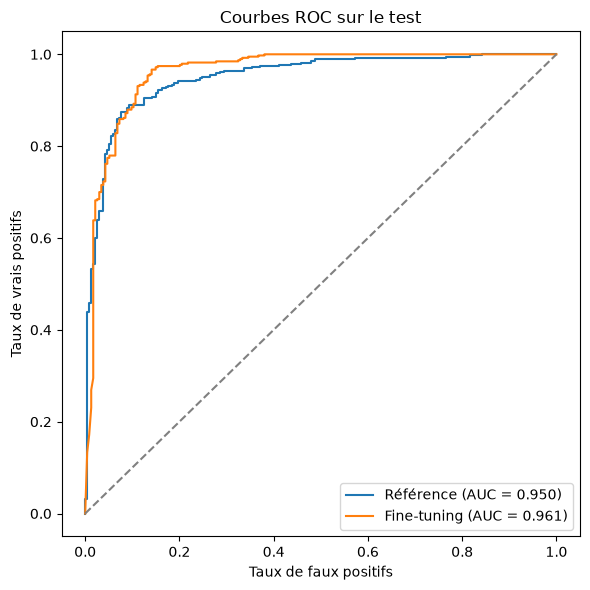

In [11]:

data_cfg = DataConfig()
device = get_device()
bundle = build_dataloaders(data_cfg)

model_ft = build_model(ModelConfig(backbone="resnet50", freeze_backbone=False), unfreeze_last_block=False).to(device)
model_ft.load_state_dict(
    torch.load(OUTPUT_DIR / "checkpoints" / "resnet50_finetune_best.pt", map_location=device, weights_only=True)
)
_, p_ft, y_ft = predict(model_ft, bundle.test, nn.CrossEntropyLoss(), device)

cache = OUTPUT_DIR / "features"
train_cache = np.load(cache / "resnet50_224_train.npz")
test_cache = np.load(cache / "resnet50_224_test.npz")
clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=ref["C_retenu"], max_iter=2000, class_weight="balanced", random_state=42),
)
clf.fit(train_cache["x"], train_cache["y"])
p_ref = clf.predict_proba(test_cache["x"])[:, POSITIVE_INDEX]
y_ref = test_cache["y"]

fig, ax = plt.subplots(figsize=(6, 6))
for nom, y, p in [("Référence", y_ref, p_ref), ("Fine-tuning", y_ft, p_ft)]:
    fpr, tpr, _ = roc_curve(y, p, pos_label=POSITIVE_INDEX)
    ax.plot(fpr, tpr, label=f"{nom} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC sur le test")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Probabilités prédites contre réalité

**Courbe de calibration (gauche).** On regroupe les images selon la probabilité prédite de pneumonie, puis on compare cette probabilité à la proportion réelle de pneumonies dans chaque groupe. Un modèle parfait suit la diagonale pointillée. Si la courbe est au-dessus, le modèle sous-estime le risque ; si elle est en dessous, il le surestime.

**Distribution des probabilités (droite).** Pour le fine-tuning, on montre les probabilités prédites séparément pour les cas normaux et les pneumonies. Plus les deux distributions sont séparées, meilleur est le tri. La ligne pointillée marque le seuil 0,5.

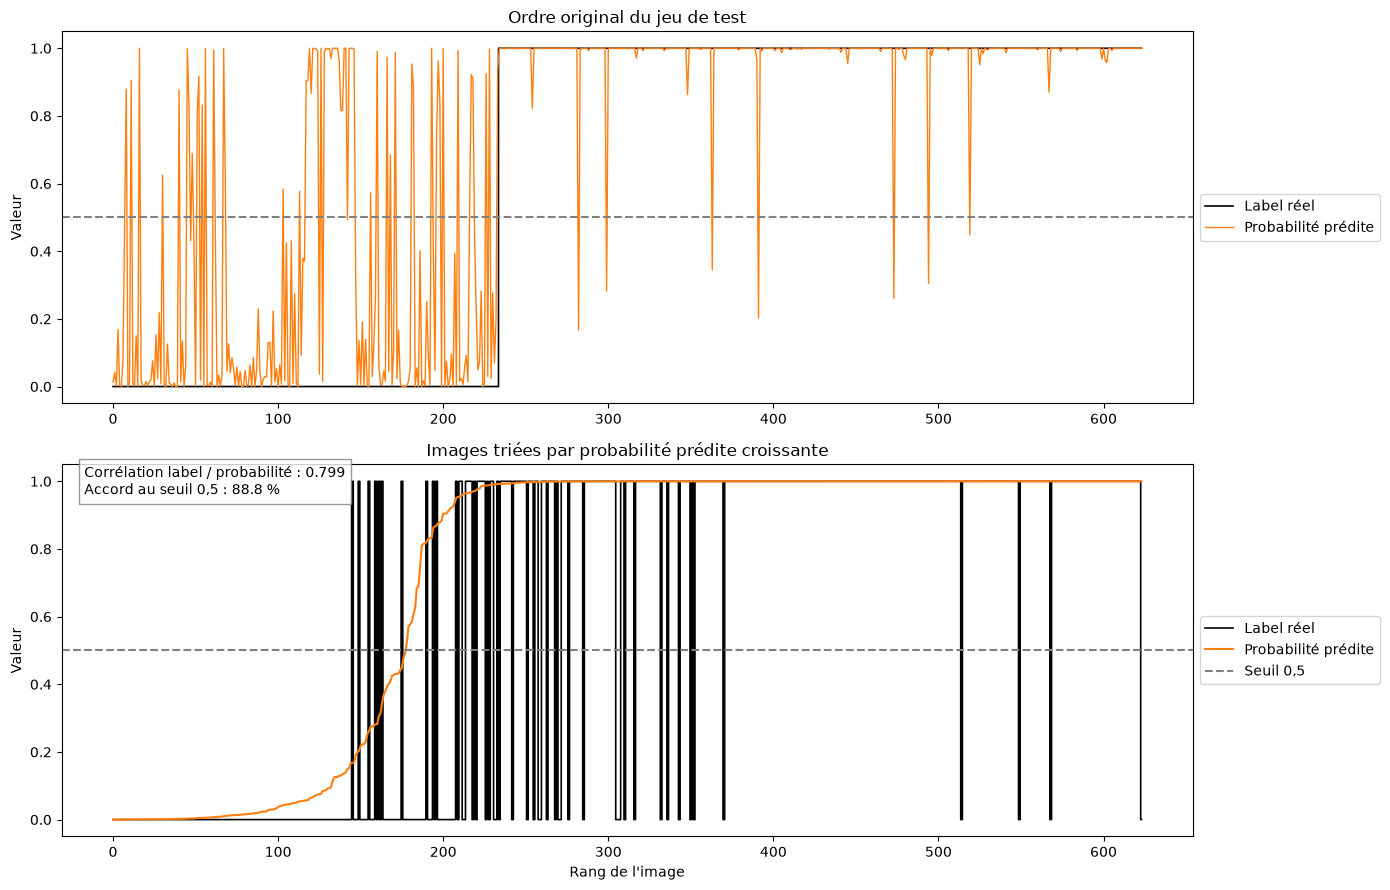

In [19]:
ordre = np.argsort(p_ft)
label_trie = y_ft[ordre]
proba_triee = p_ft[ordre]
rang = np.arange(len(ordre))
indices = np.arange(len(y_ft))

correlation = np.corrcoef(y_ft, p_ft)[0, 1]
accord = ((p_ft >= 0.5).astype(int) == y_ft).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].step(indices, y_ft, where="mid", color="black", linewidth=1.2, label="Label réel")
axes[0].plot(indices, p_ft, color="tab:orange", linewidth=1, label="Probabilité prédite")
axes[0].axhline(0.5, color="grey", linestyle="--")
axes[0].set_title("Ordre original du jeu de test")
axes[0].set_ylabel("Valeur")
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5))

axes[1].step(rang, label_trie, where="mid", color="black", linewidth=1.2, label="Label réel")
axes[1].plot(rang, proba_triee, color="tab:orange", linewidth=1.5, label="Probabilité prédite")
axes[1].axhline(0.5, color="grey", linestyle="--", label="Seuil 0,5")
axes[1].set_title("Images triées par probabilité prédite croissante")
axes[1].set_xlabel("Rang de l'image")
axes[1].set_ylabel("Valeur")
axes[1].set_ylim(-0.05, 1.05)
axes[1].text(0.02, 0.92,
             f"Corrélation label / probabilité : {correlation:.3f}\nAccord au seuil 0,5 : {accord * 100:.1f} %",
             transform=axes[1].transAxes, fontsize=10,
             bbox=dict(facecolor="white", alpha=0.8, edgecolor="grey"))
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

## 8. Conclusion

Sur le même test et au seuil 0,5, le fine-tuning complet améliore la référence sans adaptation :
- balanced accuracy de 0,772 à 0,856 ;
- ROC AUC de 0,950 à 0,961 ;
- fausses alertes ramenées de 102 à 63, pour 234 cas sains ;
- rappel de la pneumonie maintenu à 0,98, avec 7 malades manqués sur 390.

Le gain porte principalement sur la reconnaissance des cas sains, sans sacrifier la détection des pneumonies.

**Limites à rapporter** : un seul entraînement, donc la stabilité entre graines n'est pas mesurée ; l'écart entre la validation (0,975) et le test (0,856) persiste ; et les chevauchements possibles de patients entre train et test ne sont pas exclus.